In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


df_model = pd.read_excel("Cleaned_FINAL.xlsx")

In [2]:
data_ml = df_model.copy()

target_col = "NhomTrangThai"

# Các biến không dùng làm đầu vào
drop_cols = [
    "NgaySinh2",                 # Đã có biến Tuoi
    "CanhCaoHocVu_HK2",          # Thông tin HK2
    "DiemTBHocLuc_HK2",
    "XepLoaiHocLuc_HK2",
    "DiemTBTinChi_HK2",
    "STCDangKyHocKy_HK2",
    "SoTCKhongDat_HK2",
    "CoHocHK2",
    "CoHocHK3",
    "NghiHocHK1",                # Chỉ dùng để lọc dữ liệu

    # Loại các định danh nếu vẫn còn trong DataFrame
    "MaHoSo_TS",
    "IDSinhVien",
    "MaSinhVien",
    "Ten",
    "IDNganh",
    "IDLopHoc",
    "GhiChu",
    "TenTrangThai",
    "NamTotNghiep",
    "KhoaHoc",
    "NgayNhapHoc",

    #đầu vào
    # "DiemTongCong",
    # "Tuoi",
    # "TenLoaiHinhDT",
    # "TenNganh",
    # "TenKhuVuc",
    # "TenTinh",
    # "GioiTinh",
    # "TenHeDaoTao",
    # "CoDiemThiTHPT",
    # "CoDiemUuTien",
    
    #feature tốt
    "DiemHKDot1",
    
    # "CanhCaoHocVu_HK1",          # Thông tin HK1
    # "DiemTBHocLuc_HK1",
    # "XepLoaiHocLuc_HK1",
    # "DiemTBTinChi_HK1",
    # "STCDangKyHocKy_HK1",
    # "SoTCKhongDat_HK1",
    
]

# Chỉ giữ những dòng có nhãn mục tiêu hợp lệ
data_ml = data_ml[
    data_ml[target_col].isin([1, 2])
].copy()

y = data_ml[target_col].astype(int)

X = data_ml.drop(
    columns=[target_col] + drop_cols,
    errors="ignore"
).copy()

# KhoaHoc thể hiện các khóa riêng biệt, xử lý như biến phân loại
if "KhoaHoc" in X.columns:
    X["KhoaHoc"] = X["KhoaHoc"].astype("string")

print("Kích thước dữ liệu:", data_ml.shape)
print("Kích thước X:", X.shape)
print("Kích thước y:", y.shape)

print("\nPhân bố nhãn:")
print(pd.DataFrame({
    "Số lượng": y.value_counts().sort_index(),
    "Tỷ lệ (%)": (
        y.value_counts(normalize=True).sort_index() * 100
    ).round(2)
}))

print("\nCác biến đầu vào:")
print(X.columns.tolist())

Kích thước dữ liệu: (21478, 39)
Kích thước X: (21478, 16)
Kích thước y: (21478,)

Phân bố nhãn:
               Số lượng  Tỷ lệ (%)
NhomTrangThai                     
1                 12207      56.83
2                  9271      43.17

Các biến đầu vào:
['DiemTongCong', 'GioiTinh', 'TenNganh', 'TenKhuVuc', 'TenTinh', 'TenHeDaoTao', 'TenLoaiHinhDT', 'DiemTBHocLuc_HK1', 'XepLoaiHocLuc_HK1', 'DiemTBTinChi_HK1', 'CanhCaoHocVu_HK1', 'STCDangKyHocKy_HK1', 'SoTCKhongDat_HK1', 'CoDiemThiTHPT', 'CoDiemUuTien', 'Tuoi']


In [3]:
summary = pd.DataFrame({
    "Data Type": X.dtypes.astype(str),
    "Non-Null": X.notna().sum(),
    "Null": X.isna().sum(),
    "Null (%)": (X.isna().mean() * 100).round(2),
    "Unique Values": X.nunique()
})

display(summary)

,Data Type,Non-Null,Null,Null (%),Unique Values
DiemTongCong,float64,20690,788,3.67,176
GioiTinh,bool,21478,0,0.00,2
TenNganh,str,21478,0,0.00,47
TenKhuVuc,str,21478,0,0.00,5
TenTinh,str,21478,0,0.00,66
TenHeDaoTao,str,21478,0,0.00,2
TenLoaiHinhDT,str,21478,0,0.00,12
DiemTBHocLuc_HK1,float64,21478,0,0.00,939
XepLoaiHocLuc_HK1,str,21478,0,0.00,7
DiemTBTinChi_HK1,float64,21478,0,0.00,374


In [4]:
from sklearn.model_selection import train_test_split

# Tách riêng 15% test
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=2026,
    stratify=y
)

# Tách phần còn lại thành 70% train và 15% validation
# 15 / 85 = khoảng 17.65% của phần còn lại
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=15/85,
    random_state=2026,
    stratify=y_train_val
)

# Kiểm tra số lượng và tỷ lệ các lớp
for name, labels in [
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:
    print(f"\n{name}: {len(labels):,} quan sát")
    print(
        (labels.value_counts(normalize=True)
         .sort_index() * 100).round(2)
    )


Train: 15,034 quan sát
NhomTrangThai
1    56.84
2    43.16
Name: proportion, dtype: float64

Validation: 3,222 quan sát
NhomTrangThai
1    56.83
2    43.17
Name: proportion, dtype: float64

Test: 3,222 quan sát
NhomTrangThai
1    56.83
2    43.17
Name: proportion, dtype: float64


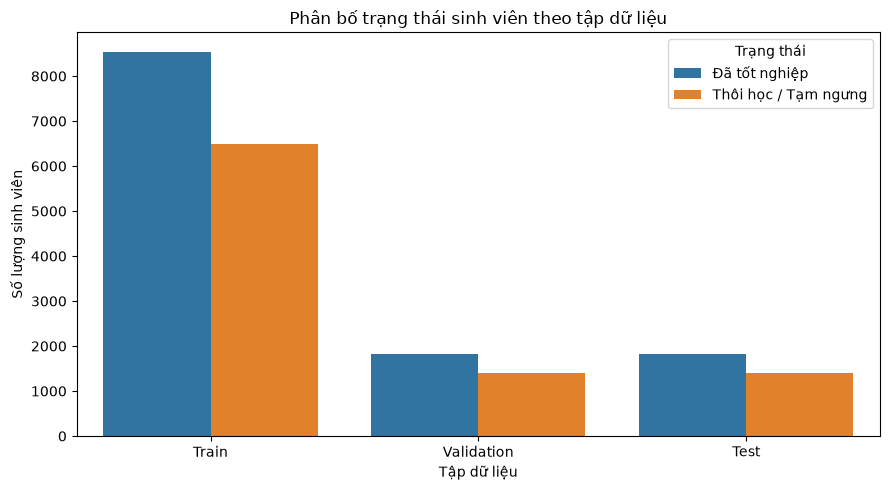

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

split_data = pd.concat([
    pd.DataFrame({"NhomTrangThai": y_train, "Tap": "Train"}),
    pd.DataFrame({"NhomTrangThai": y_val, "Tap": "Validation"}),
    pd.DataFrame({"NhomTrangThai": y_test, "Tap": "Test"})
], ignore_index=True)

split_data["TrangThai"] = split_data["NhomTrangThai"].map({
    1: "Đã tốt nghiệp",
    2: "Thôi học / Tạm ngưng"
})

plt.figure(figsize=(9, 5))
sns.countplot(
    data=split_data,
    x="Tap",
    hue="TrangThai"
)
plt.title("Phân bố trạng thái sinh viên theo tập dữ liệu")
plt.xlabel("Tập dữ liệu")
plt.ylabel("Số lượng sinh viên")
plt.legend(title="Trạng thái")
plt.tight_layout()
plt.show()

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Nhận diện kiểu dữ liệu dựa trên tập train
categorical_cols = X_train.select_dtypes(
    include=["object", "category", "bool", "string"]
).columns.tolist()

numeric_cols = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

print("Biến số:", numeric_cols)
print("\nBiến phân loại:", categorical_cols)


def create_preprocessor():
    numeric_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer(transformers=[
        ("num", numeric_pipeline, numeric_cols),
        ("cat", categorical_pipeline, categorical_cols)
    ])

Biến số: ['DiemTongCong', 'DiemTBHocLuc_HK1', 'DiemTBTinChi_HK1', 'CanhCaoHocVu_HK1', 'STCDangKyHocKy_HK1', 'SoTCKhongDat_HK1', 'Tuoi']

Biến phân loại: ['GioiTinh', 'TenNganh', 'TenKhuVuc', 'TenTinh', 'TenHeDaoTao', 'TenLoaiHinhDT', 'XepLoaiHocLuc_HK1', 'CoDiemThiTHPT', 'CoDiemUuTien']


In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

models = {
    "Logistic Regression": Pipeline(steps=[
        ("preprocessor", create_preprocessor()),
        ("classifier", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ]),

    "Decision Tree": Pipeline(steps=[
        ("preprocessor", create_preprocessor()),
        ("classifier", DecisionTreeClassifier(
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline(steps=[
        ("preprocessor", create_preprocessor()),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ])
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"Đã huấn luyện: {name}")

Đã huấn luyện: Logistic Regression
Đã huấn luyện: Decision Tree
Đã huấn luyện: Random Forest


In [8]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

def evaluate_model(model, X_eval, y_eval):
    y_pred = model.predict(X_eval)

    # Lấy xác suất thuộc lớp 2: Thôi học / Tạm ngưng
    classifier = model.named_steps["classifier"]
    class2_index = list(classifier.classes_).index(2)
    y_prob = model.predict_proba(X_eval)[:, class2_index]

    return {
        "Accuracy": accuracy_score(y_eval, y_pred),
        "Precision_Lop2": precision_score(
            y_eval, y_pred, pos_label=2, zero_division=0
        ),
        "Recall_Lop2": recall_score(
            y_eval, y_pred, pos_label=2, zero_division=0
        ),
        "F1_Lop2": f1_score(
            y_eval, y_pred, pos_label=2, zero_division=0
        ),
        "Macro_F1": f1_score(
            y_eval, y_pred, average="macro", zero_division=0
        ),
        "ROC_AUC": roc_auc_score(
            (y_eval == 2).astype(int), y_prob
        )
    }


baseline_results = []

for name, model in models.items():
    train_scores = evaluate_model(model, X_train, y_train)
    val_scores = evaluate_model(model, X_val, y_val)

    row = {"Model": name}

    for metric, value in train_scores.items():
        row[f"Train_{metric}"] = value

    for metric, value in val_scores.items():
        row[f"Val_{metric}"] = value

    baseline_results.append(row)

baseline_df = pd.DataFrame(baseline_results).set_index("Model")

display(baseline_df.round(3))

,Train_Accuracy,Train_Precision_Lop2,Train_Recall_Lop2,Train_F1_Lop2,Train_Macro_F1,Train_ROC_AUC,Val_Accuracy,Val_Precision_Lop2,Val_Recall_Lop2,Val_F1_Lop2,Val_Macro_F1,Val_ROC_AUC
Model,,,,,,,,,,,,
Logistic Regression,0.807,0.855,0.666,0.749,0.796,0.872,0.794,0.832,0.654,0.732,0.782,0.859
Decision Tree,1.000,1.000,1.000,1.000,1.000,1.000,0.726,0.681,0.686,0.683,0.721,0.721
Random Forest,1.000,1.000,1.000,1.000,1.000,1.000,0.801,0.829,0.679,0.747,0.791,0.862


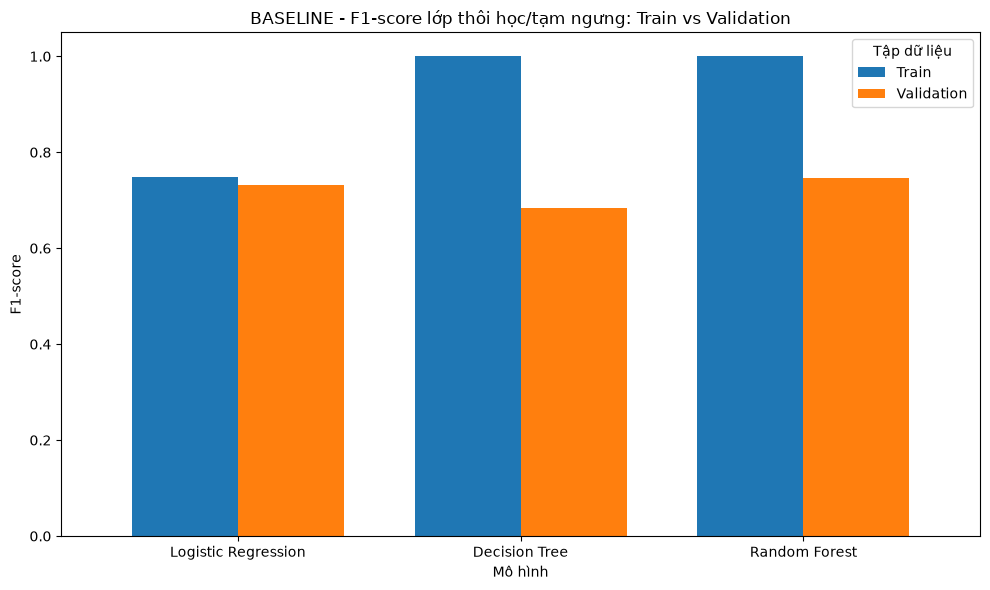

In [9]:
# baseline_df đã được tạo ở Block 3.1
f1_plot_df = (
    baseline_df[["Train_F1_Lop2", "Val_F1_Lop2"]]
    .rename(columns={
        "Train_F1_Lop2": "Train",
        "Val_F1_Lop2": "Validation"
    })
)

ax = f1_plot_df.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.75
)

ax.set_title("BASELINE - F1-score lớp thôi học/tạm ngưng: Train vs Validation")
ax.set_xlabel("Mô hình")
ax.set_ylabel("F1-score")
ax.set_ylim(0, 1.05)
ax.legend(title="Tập dữ liệu")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

<Figure size 1200x600 with 0 Axes>

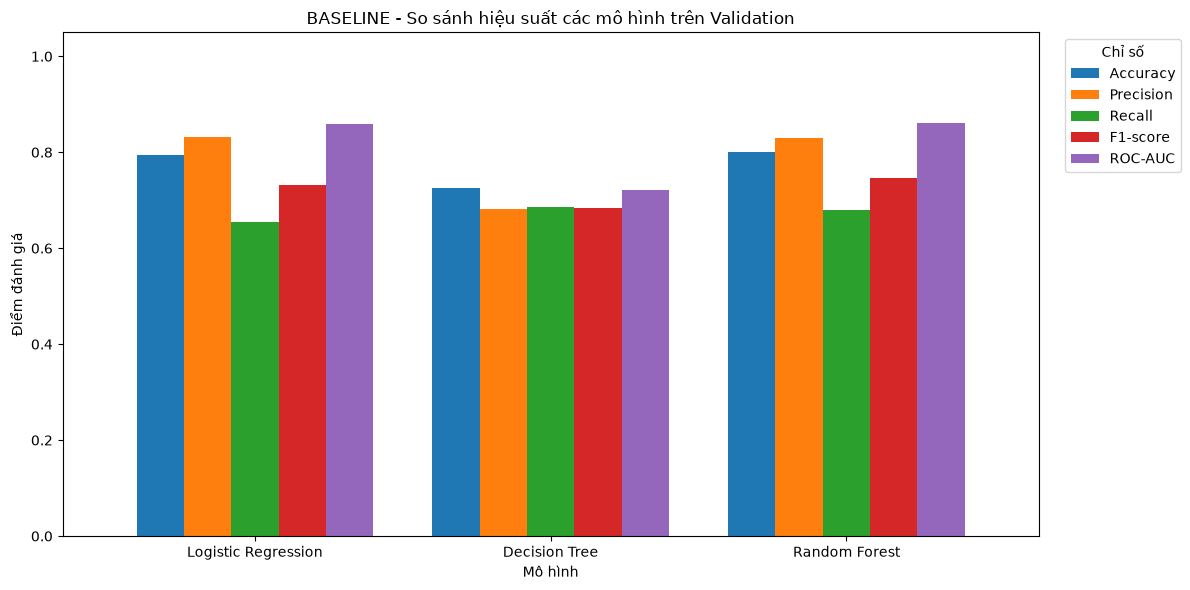

In [10]:
metrics = [
    "Accuracy",
    "Precision_Lop2",
    "Recall_Lop2",
    "F1_Lop2",
    "ROC_AUC"
]

metric_names = {
    "Accuracy": "Accuracy",
    "Precision_Lop2": "Precision",
    "Recall_Lop2": "Recall",
    "F1_Lop2": "F1-score",
    "ROC_AUC": "ROC-AUC"
}

val_plot_df = (
    baseline_df[[f"Val_{metric}" for metric in metrics]]
    .copy()
)

val_plot_df.columns = [
    metric_names[metric] for metric in metrics
]

plt.figure(figsize=(12, 6))
val_plot_df.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("BASELINE - So sánh hiệu suất các mô hình trên Validation")
plt.xlabel("Mô hình")
plt.ylabel("Điểm đánh giá")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(title="Chỉ số", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


Logistic Regression
                      precision    recall  f1-score   support

       Đã tốt nghiệp      0.774     0.900     0.832      1831
Thôi học / Tạm ngưng      0.832     0.654     0.732      1391

            accuracy                          0.794      3222
           macro avg      0.803     0.777     0.782      3222
        weighted avg      0.799     0.794     0.789      3222



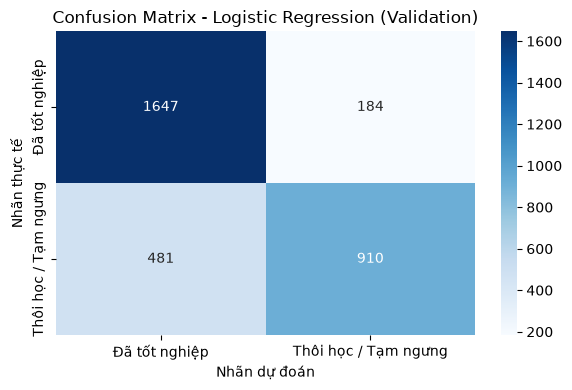


Decision Tree
                      precision    recall  f1-score   support

       Đã tốt nghiệp      0.760     0.756     0.758      1831
Thôi học / Tạm ngưng      0.681     0.686     0.683      1391

            accuracy                          0.726      3222
           macro avg      0.720     0.721     0.721      3222
        weighted avg      0.726     0.726     0.726      3222



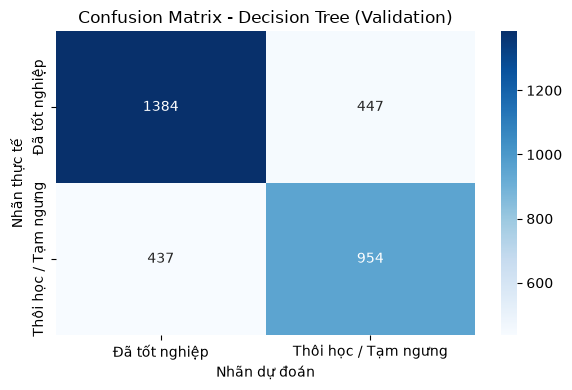


Random Forest
                      precision    recall  f1-score   support

       Đã tốt nghiệp      0.786     0.894     0.836      1831
Thôi học / Tạm ngưng      0.829     0.679     0.747      1391

            accuracy                          0.801      3222
           macro avg      0.807     0.786     0.791      3222
        weighted avg      0.804     0.801     0.798      3222



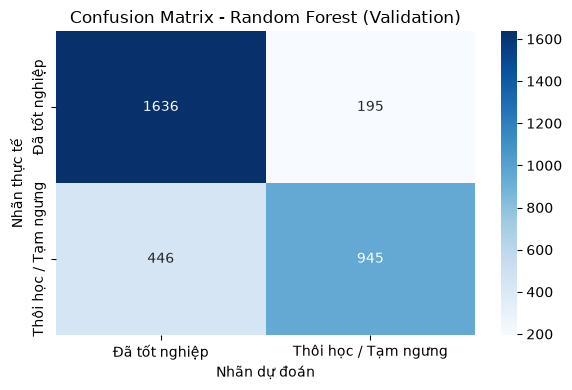

In [11]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

class_labels = [1, 2]
class_names = ["Đã tốt nghiệp", "Thôi học / Tạm ngưng"]

for name, model in models.items():
    y_pred = model.predict(X_val)

    print(f"\n{'=' * 55}")
    print(name)
    print("=" * 55)

    print(classification_report(
        y_val,
        y_pred,
        labels=class_labels,
        target_names=class_names,
        digits=3,
        zero_division=0
    ))

    cm = confusion_matrix(
        y_val,
        y_pred,
        labels=class_labels
    )

    plt.figure(figsize=(6, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names
    )
    plt.title(f"Confusion Matrix - {name} (Validation)")
    plt.xlabel("Nhãn dự đoán")
    plt.ylabel("Nhãn thực tế")
    plt.tight_layout()
    plt.show()

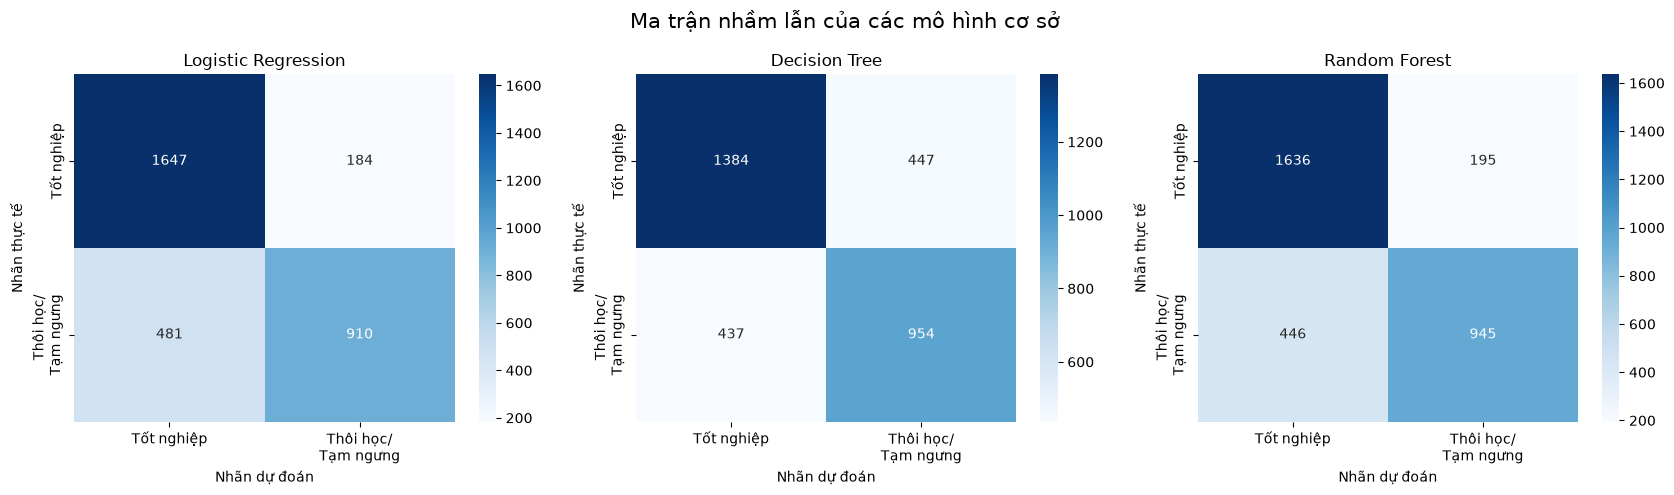

In [12]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

class_labels = [1, 2]
class_names = ["Tốt nghiệp", "Thôi học/\nTạm ngưng"]

for ax, (name, model) in zip(axes, models.items()):
    y_pred = model.predict(X_val)

    cm = confusion_matrix(
        y_val,
        y_pred,
        labels=class_labels
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Nhãn dự đoán")
    ax.set_ylabel("Nhãn thực tế")

plt.suptitle("Ma trận nhầm lẫn của các mô hình cơ sở", fontsize=15)
plt.tight_layout()
plt.show()

In [13]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import make_scorer, f1_score

# Ưu tiên F1-score của lớp 2: Thôi học / Tạm ngưng
f1_lop2_scorer = make_scorer(f1_score, pos_label=2)

# 5-fold stratified cross-validation
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Không gian tham số cho từng mô hình
param_grids = {
    "Logistic Regression": {
        "classifier__C": [0.01, 0.1, 1, 10],
        "classifier__class_weight": [None, "balanced"]
    },

    "Decision Tree": {
        "classifier__max_depth": [None, 5, 10, 15],
        "classifier__min_samples_split": [2, 10],
        "classifier__min_samples_leaf": [1, 5, 10],
        "classifier__class_weight": [None, "balanced"]
    },

    "Random Forest": {
        "classifier__n_estimators": [100, 200],
        "classifier__max_depth": [None, 10, 20],
        "classifier__min_samples_leaf": [1, 3, 5],
        "classifier__class_weight": [None, "balanced"]
    }
}

In [14]:
best_models = {}
grid_results = []
cv_results_detail = {}

for name, base_model in models.items():
    print(f"\n{'=' * 60}")
    print(f"Đang fine-tune: {name}")
    print("=" * 60)

    # Tránh chạy song song lồng nhau khi GridSearchCV dùng nhiều CPU
    if name == "Random Forest":
        base_model.set_params(classifier__n_jobs=1)

    grid_search = GridSearchCV(
        estimator=base_model,
        param_grid=param_grids[name],
        scoring=f1_lop2_scorer,
        cv=cv_strategy,
        n_jobs=-1,
        refit=True,
        return_train_score=True,
        verbose=1
    )

    # Chỉ dùng train; không dùng validation hoặc test để tìm tham số
    grid_search.fit(X_train, y_train)

    best_models[name] = grid_search.best_estimator_
    cv_results_detail[name] = pd.DataFrame(grid_search.cv_results_)

    grid_results.append({
        "Model": name,
        "Best_CV_F1_Lop2": grid_search.best_score_,
        "Best_Params": grid_search.best_params_,
        "CV_Train_F1": grid_search.cv_results_[
            "mean_train_score"
        ][grid_search.best_index_]
    })

    print("F1-score tốt nhất trên CV:", round(grid_search.best_score_, 4))
    print("Bộ tham số tốt nhất:", grid_search.best_params_)

grid_summary_df = (
    pd.DataFrame(grid_results)
    .sort_values("Best_CV_F1_Lop2", ascending=False)
    .reset_index(drop=True)
)

display(grid_summary_df)


Đang fine-tune: Logistic Regression
Fitting 5 folds for each of 8 candidates, totalling 40 fits
F1-score tốt nhất trên CV: 0.7543
Bộ tham số tốt nhất: {'classifier__C': 0.1, 'classifier__class_weight': 'balanced'}

Đang fine-tune: Decision Tree
Fitting 5 folds for each of 48 candidates, totalling 240 fits
F1-score tốt nhất trên CV: 0.7403
Bộ tham số tốt nhất: {'classifier__class_weight': 'balanced', 'classifier__max_depth': 5, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2}

Đang fine-tune: Random Forest
Fitting 5 folds for each of 36 candidates, totalling 180 fits
F1-score tốt nhất trên CV: 0.7547
Bộ tham số tốt nhất: {'classifier__class_weight': 'balanced', 'classifier__max_depth': 20, 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 200}


,Model,Best_CV_F1_Lop2,Best_Params,CV_Train_F1
0,Random Forest,0.754692,"{'classifier__class_weight': 'balanced', 'clas...",0.905621
1,Logistic Regression,0.754285,"{'classifier__C': 0.1, 'classifier__class_weig...",0.758810
2,Decision Tree,0.740256,"{'classifier__class_weight': 'balanced', 'clas...",0.751710


In [15]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd
import numpy as np

results = []

for name, model in best_models.items():

    # Dự đoán trên Train
    y_train_pred = model.predict(X_train)
    train_classes = list(model.named_steps["classifier"].classes_)
    class2_idx = train_classes.index(2)
    y_train_prob = model.predict_proba(X_train)[:, class2_idx]

    # Dự đoán trên Validation
    y_val_pred = model.predict(X_val)
    y_val_prob = model.predict_proba(X_val)[:, class2_idx]

    # Nhãn nhị phân phục vụ ROC-AUC
    y_train_binary = (y_train == 2).astype(int)
    y_val_binary = (y_val == 2).astype(int)

    results.append({
        "Model": name,

        "Train_Accuracy": accuracy_score(y_train, y_train_pred),
        "Train_Precision_Lop2": precision_score(
            y_train, y_train_pred, pos_label=2, zero_division=0
        ),
        "Train_Recall_Lop2": recall_score(
            y_train, y_train_pred, pos_label=2, zero_division=0
        ),
        "Train_F1_Lop2": f1_score(
            y_train, y_train_pred, pos_label=2, zero_division=0
        ),
        "Train_ROC_AUC": roc_auc_score(
            y_train_binary, y_train_prob
        ),

        "Val_Accuracy": accuracy_score(y_val, y_val_pred),
        "Val_Precision_Lop2": precision_score(
            y_val, y_val_pred, pos_label=2, zero_division=0
        ),
        "Val_Recall_Lop2": recall_score(
            y_val, y_val_pred, pos_label=2, zero_division=0
        ),
        "Val_F1_Lop2": f1_score(
            y_val, y_val_pred, pos_label=2, zero_division=0
        ),
        "Val_ROC_AUC": roc_auc_score(
            y_val_binary, y_val_prob
        )
    })

train_val_df = pd.DataFrame(results)

# Sắp xếp theo F1-score trên Validation
train_val_df = train_val_df.sort_values(
    "Val_F1_Lop2",
    ascending=False
).reset_index(drop=True)

display(train_val_df.round(3))

,Model,Train_Accuracy,Train_Precision_Lop2,Train_Recall_Lop2,Train_F1_Lop2,Train_ROC_AUC,Val_Accuracy,Val_Precision_Lop2,Val_Recall_Lop2,Val_F1_Lop2,Val_ROC_AUC
0,Random Forest,0.915,0.962,0.835,0.894,0.982,0.802,0.813,0.705,0.755,0.863
1,Logistic Regression,0.805,0.818,0.706,0.758,0.871,0.792,0.799,0.694,0.743,0.859
2,Decision Tree,0.800,0.824,0.684,0.747,0.858,0.787,0.801,0.675,0.732,0.839


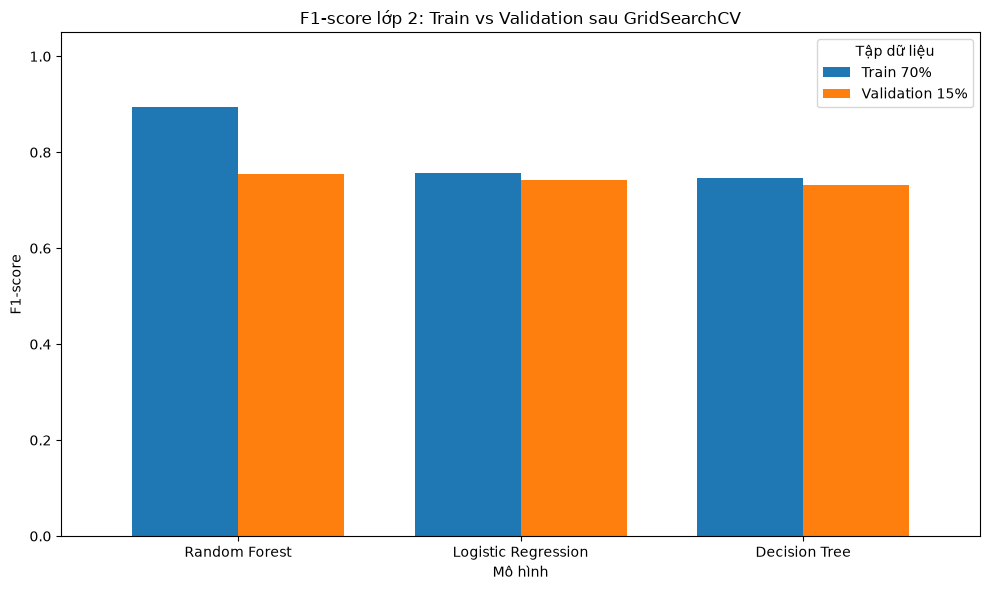

In [16]:
import matplotlib.pyplot as plt

f1_plot_df = (
    train_val_df.set_index("Model")[
        ["Train_F1_Lop2", "Val_F1_Lop2"]
    ]
    .rename(columns={
        "Train_F1_Lop2": "Train 70%",
        "Val_F1_Lop2": "Validation 15%"
    })
)

ax = f1_plot_df.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.75
)

ax.set_title("F1-score lớp 2: Train vs Validation sau GridSearchCV")
ax.set_xlabel("Mô hình")
ax.set_ylabel("F1-score")
ax.set_ylim(0, 1.05)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Tập dữ liệu")

plt.tight_layout()
plt.show()

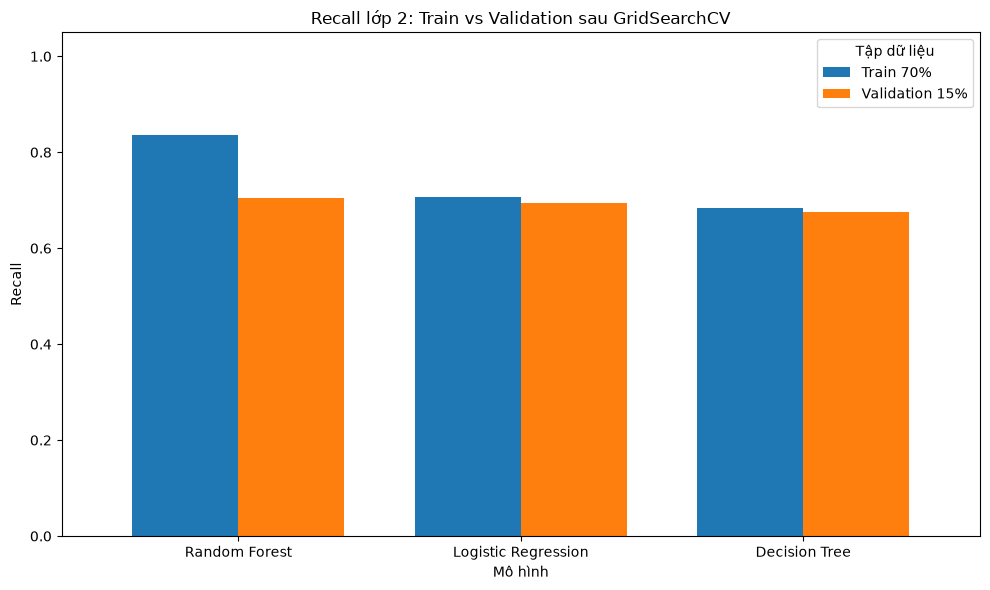

In [17]:
recall_plot_df = (
    train_val_df.set_index("Model")[
        ["Train_Recall_Lop2", "Val_Recall_Lop2"]
    ]
    .rename(columns={
        "Train_Recall_Lop2": "Train 70%",
        "Val_Recall_Lop2": "Validation 15%"
    })
)

ax = recall_plot_df.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.75
)

ax.set_title("Recall lớp 2: Train vs Validation sau GridSearchCV")
ax.set_xlabel("Mô hình")
ax.set_ylabel("Recall")
ax.set_ylim(0, 1.05)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Tập dữ liệu")

plt.tight_layout()
plt.show()

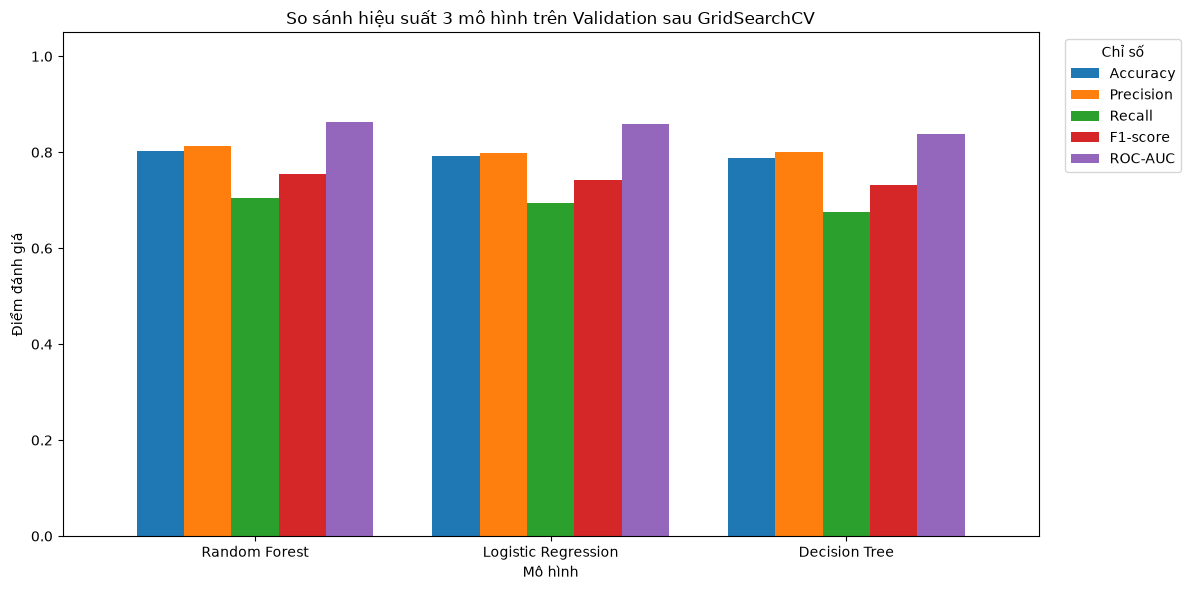

In [18]:
validation_metrics = {
    "Val_Accuracy": "Accuracy",
    "Val_Precision_Lop2": "Precision",
    "Val_Recall_Lop2": "Recall",
    "Val_F1_Lop2": "F1-score",
    "Val_ROC_AUC": "ROC-AUC"
}

val_metrics_df = (
    train_val_df.set_index("Model")[
        list(validation_metrics.keys())
    ]
    .rename(columns=validation_metrics)
)

ax = val_metrics_df.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

ax.set_title("So sánh hiệu suất 3 mô hình trên Validation sau GridSearchCV")
ax.set_xlabel("Mô hình")
ax.set_ylabel("Điểm đánh giá")
ax.set_ylim(0, 1.05)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Chỉ số", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

In [19]:
comparison_results = []

# Baseline trên validation
for name, model in models.items():
    scores = evaluate_model(model, X_val, y_val)

    comparison_results.append({
        "Model": name,
        "Stage": "Baseline",
        **scores
    })

# Mô hình đã fine-tune trên validation
for name, model in best_models.items():
    scores = evaluate_model(model, X_val, y_val)

    comparison_results.append({
        "Model": name,
        "Stage": "Tuned",
        **scores
    })

comparison_df = pd.DataFrame(comparison_results)

display(
    comparison_df.sort_values(
        ["Model", "Stage"]
    ).round(3)
)

,Model,Stage,Accuracy,Precision_Lop2,Recall_Lop2,F1_Lop2,Macro_F1,ROC_AUC
1,Decision Tree,Baseline,0.726,0.681,0.686,0.683,0.721,0.721
4,Decision Tree,Tuned,0.787,0.801,0.675,0.732,0.778,0.839
0,Logistic Regression,Baseline,0.794,0.832,0.654,0.732,0.782,0.859
3,Logistic Regression,Tuned,0.792,0.799,0.694,0.743,0.784,0.859
2,Random Forest,Baseline,0.801,0.829,0.679,0.747,0.791,0.862
5,Random Forest,Tuned,0.802,0.813,0.705,0.755,0.795,0.863


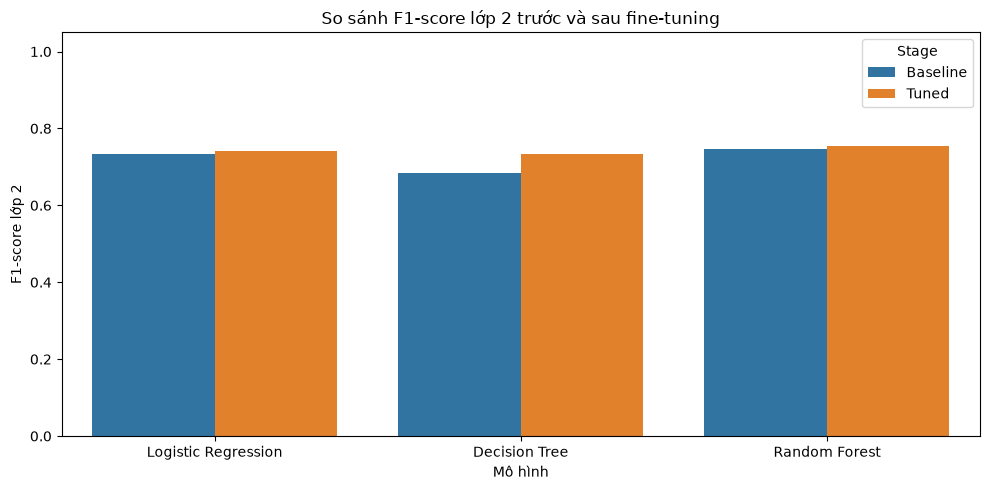

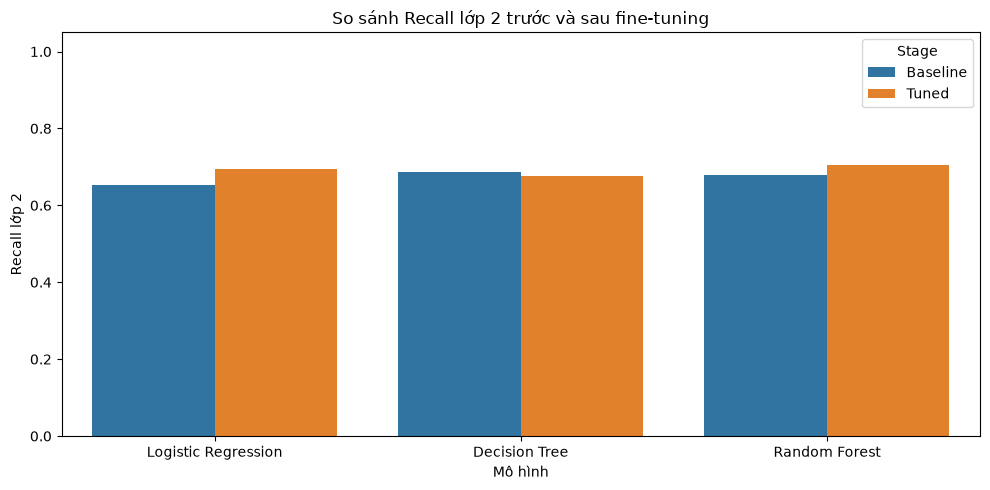

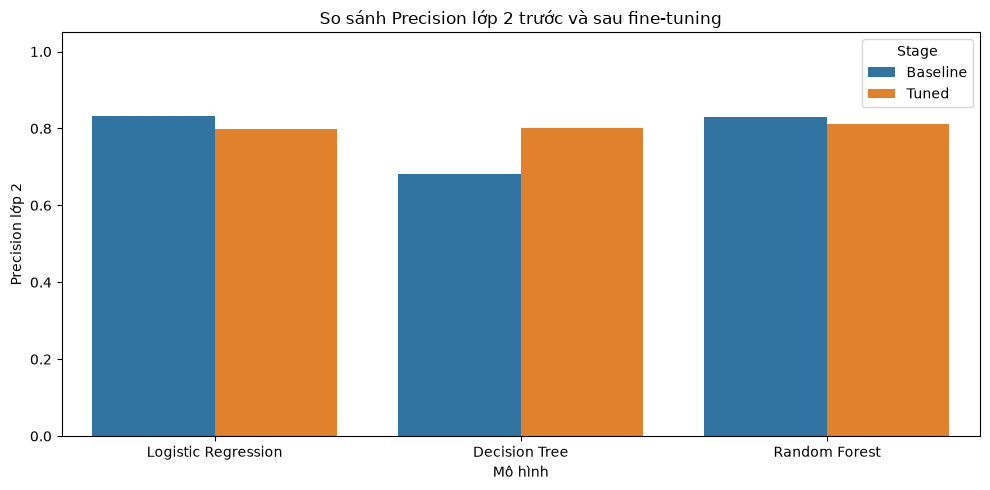

In [20]:
for metric, title in [
    ("F1_Lop2", "F1-score lớp 2"),
    ("Recall_Lop2", "Recall lớp 2"),
    ("Precision_Lop2", "Precision lớp 2")
]:
    plt.figure(figsize=(10, 5))

    sns.barplot(
        data=comparison_df,
        x="Model",
        y=metric,
        hue="Stage"
    )

    plt.title(f"So sánh {title} trước và sau fine-tuning")
    plt.xlabel("Mô hình")
    plt.ylabel(title)
    plt.ylim(0, 1.05)
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

In [21]:
# Lưu kết quả trước khi chạy lại các cell
#baseline_full_df = baseline_df.copy()
#grid_summary_full_df = grid_summary_df.copy()
#tuned_val_full_df = tuned_val_df.copy()

In [22]:
final_model = best_models["Decision Tree"]

print("Các tham số của Decision Tree đã chọn:")
print(final_model.named_steps["classifier"].get_params())

Các tham số của Decision Tree đã chọn:
{'ccp_alpha': 0.0, 'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 5, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': 42, 'splitter': 'best'}


In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score
)

# Lấy xác suất thuộc lớp 2
classifier = final_model.named_steps["classifier"]
class2_idx = list(classifier.classes_).index(2)

val_prob = final_model.predict_proba(X_val)[:, class2_idx]
y_val_binary = (y_val == 2).astype(int)

# Tính Precision và Recall tại các ngưỡng
val_precision, val_recall, val_thresholds = (
    precision_recall_curve(y_val_binary, val_prob)
)

# precision và recall dài hơn thresholds một phần tử
val_f1_curve = (
    2 * val_precision[:-1] * val_recall[:-1]
    / (
        val_precision[:-1] + val_recall[:-1] + 1e-12
    )
)

best_idx = np.argmax(val_f1_curve)
best_threshold = float(val_thresholds[best_idx])

print(f"Ngưỡng được chọn: {best_threshold:.4f}")
print(f"Validation Precision: {val_precision[best_idx]:.3f}")
print(f"Validation Recall:    {val_recall[best_idx]:.3f}")
print(f"Validation F1-score:  {val_f1_curve[best_idx]:.3f}")

Ngưỡng được chọn: 0.4892
Validation Precision: 0.742
Validation Recall:    0.733
Validation F1-score:  0.737


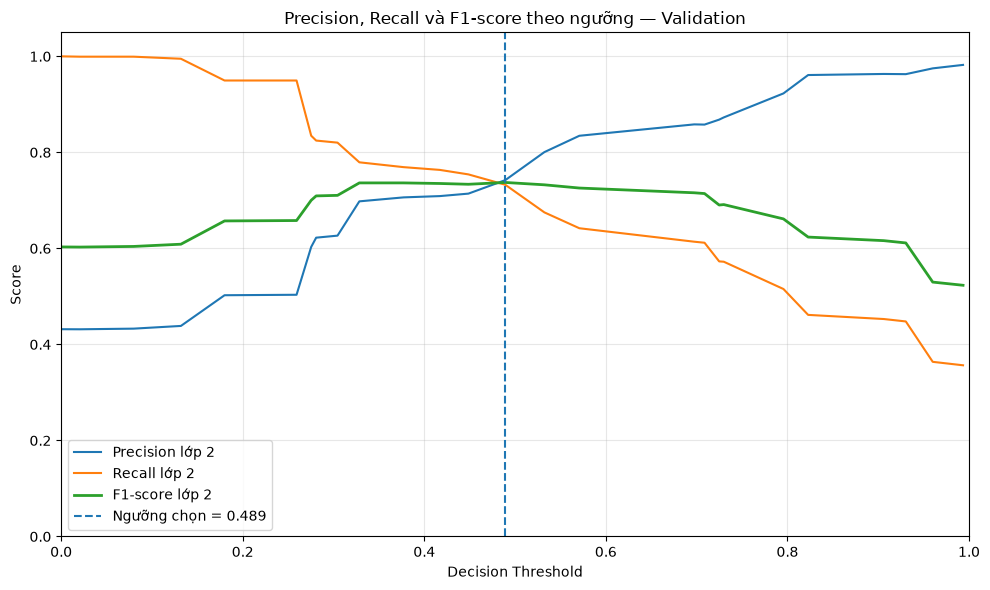

In [24]:
plt.figure(figsize=(10, 6))

plt.plot(
    val_thresholds,
    val_precision[:-1],
    label="Precision lớp 2"
)
plt.plot(
    val_thresholds,
    val_recall[:-1],
    label="Recall lớp 2"
)
plt.plot(
    val_thresholds,
    val_f1_curve,
    label="F1-score lớp 2",
    linewidth=2
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label=f"Ngưỡng chọn = {best_threshold:.3f}"
)

plt.title("Precision, Recall và F1-score theo ngưỡng — Validation")
plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.xlim(0, 1)
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

,Threshold,Accuracy,Precision_Lop2,Recall_Lop2,F1_Lop2,Macro_F1,ROC_AUC,Average_Precision
0,0.489,0.792,0.761,0.756,0.758,0.788,0.853,0.848


                      precision    recall  f1-score   support

       Đã tốt nghiệp      0.816     0.819     0.817      1831
Thôi học / Tạm ngưng      0.761     0.756     0.758      1391

            accuracy                          0.792      3222
           macro avg      0.788     0.788     0.788      3222
        weighted avg      0.792     0.792     0.792      3222



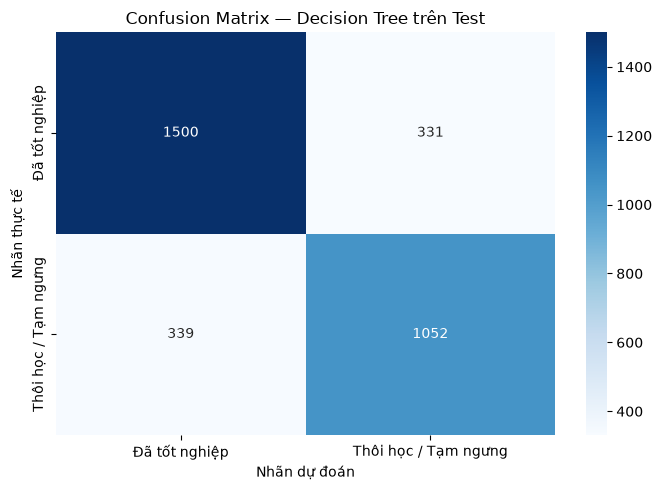

In [25]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    roc_auc_score,
    average_precision_score
)
import seaborn as sns

# Xác suất trên Test
test_prob = final_model.predict_proba(X_test)[:, class2_idx]
y_test_binary = (y_test == 2).astype(int)

# Dự đoán theo ngưỡng đã chọn từ Validation
y_test_pred = np.where(test_prob >= best_threshold, 2, 1)

# Bảng đánh giá
test_results = pd.DataFrame([{
    "Threshold": best_threshold,
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "Precision_Lop2": precision_score(
        y_test, y_test_pred, pos_label=2, zero_division=0
    ),
    "Recall_Lop2": recall_score(
        y_test, y_test_pred, pos_label=2, zero_division=0
    ),
    "F1_Lop2": f1_score(
        y_test, y_test_pred, pos_label=2, zero_division=0
    ),
    "Macro_F1": f1_score(
        y_test, y_test_pred, average="macro", zero_division=0
    ),
    "ROC_AUC": roc_auc_score(y_test_binary, test_prob),
    "Average_Precision": average_precision_score(
        y_test_binary, test_prob
    )
}])

display(test_results.round(3))

print(classification_report(
    y_test,
    y_test_pred,
    labels=[1, 2],
    target_names=["Đã tốt nghiệp", "Thôi học / Tạm ngưng"],
    digits=3,
    zero_division=0
))

cm = confusion_matrix(y_test, y_test_pred, labels=[1, 2])

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Đã tốt nghiệp", "Thôi học / Tạm ngưng"],
    yticklabels=["Đã tốt nghiệp", "Thôi học / Tạm ngưng"]
)

plt.title("Confusion Matrix — Decision Tree trên Test")
plt.xlabel("Nhãn dự đoán")
plt.ylabel("Nhãn thực tế")
plt.tight_layout()
plt.show()

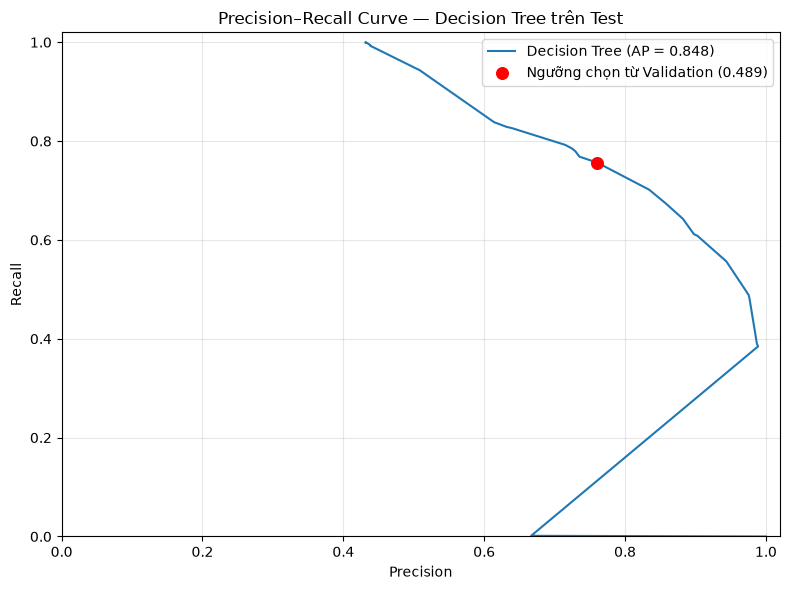

In [26]:
test_precision_curve, test_recall_curve, _ = (
    precision_recall_curve(y_test_binary, test_prob)
)

# Điểm hoạt động của ngưỡng được chọn trên Validation
test_precision_at_threshold = precision_score(
    y_test, y_test_pred, pos_label=2, zero_division=0
)
test_recall_at_threshold = recall_score(
    y_test, y_test_pred, pos_label=2, zero_division=0
)

ap_score = average_precision_score(y_test_binary, test_prob)

plt.figure(figsize=(8, 6))

# Trục hoành là Precision, trục tung là Recall để gần giống bài mẫu
plt.plot(
    test_precision_curve,
    test_recall_curve,
    label=f"Decision Tree (AP = {ap_score:.3f})"
)

plt.scatter(
    test_precision_at_threshold,
    test_recall_at_threshold,
    color="red",
    s=70,
    label=f"Ngưỡng chọn từ Validation ({best_threshold:.3f})",
    zorder=3
)

plt.title("Precision–Recall Curve — Decision Tree trên Test")
plt.xlabel("Precision")
plt.ylabel("Recall")
plt.xlim(0, 1.02)
plt.ylim(0, 1.02)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

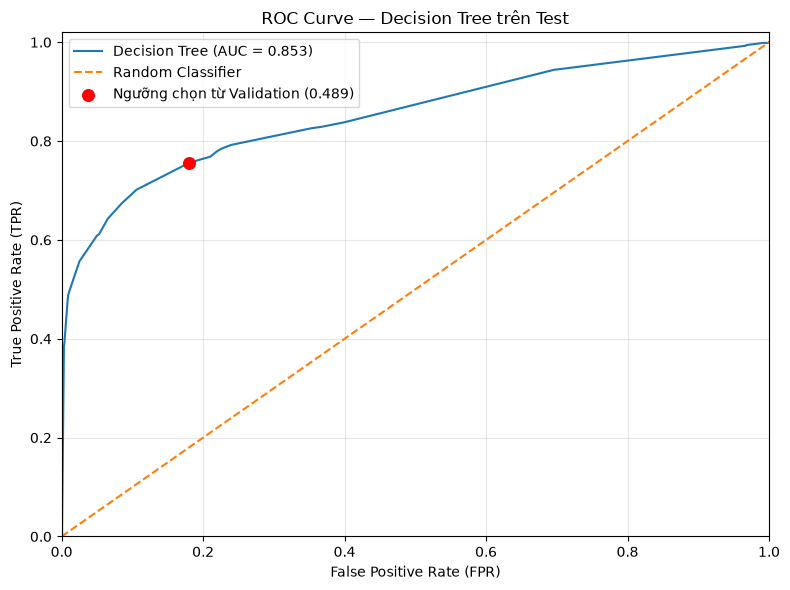

In [27]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, roc_thresholds = roc_curve(y_test_binary, test_prob)
roc_auc = roc_auc_score(y_test_binary, test_prob)

# Xác định điểm hoạt động ở ngưỡng đã chốt từ Validation
cm_binary = confusion_matrix(
    y_test_binary,
    (test_prob >= best_threshold).astype(int),
    labels=[0, 1]
)
tn, fp, fn, tp = cm_binary.ravel()

fpr_selected = fp / (fp + tn) if (fp + tn) else 0
tpr_selected = tp / (tp + fn) if (tp + fn) else 0

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Decision Tree (AUC = {roc_auc:.3f})"
)
plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.scatter(
    fpr_selected,
    tpr_selected,
    color="red",
    s=70,
    label=f"Ngưỡng chọn từ Validation ({best_threshold:.3f})",
    zorder=3
)

plt.title("ROC Curve — Decision Tree trên Test")
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

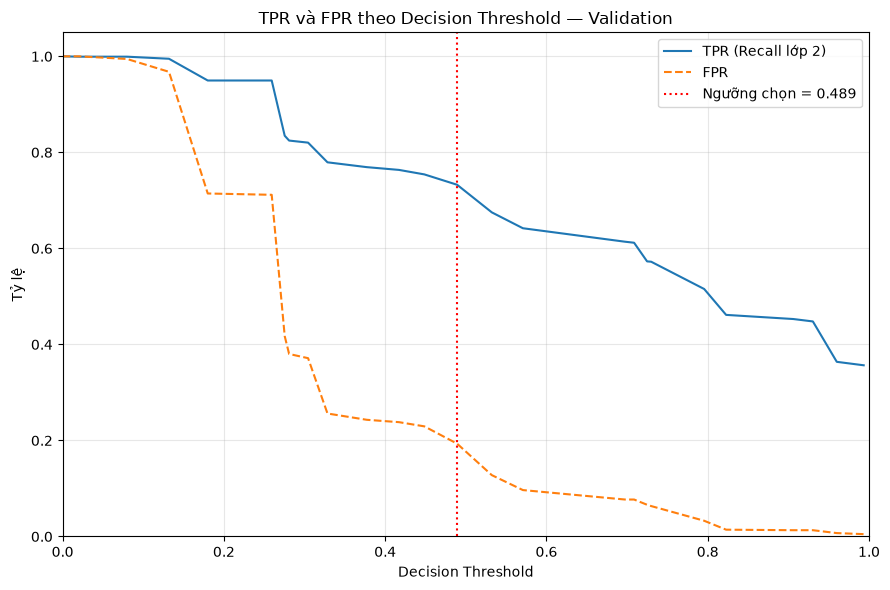

In [28]:
from sklearn.metrics import roc_curve

val_fpr, val_tpr, val_roc_thresholds = roc_curve(
    y_val_binary,
    val_prob
)

# Loại ngưỡng vô cực và sắp xếp ngưỡng theo chiều tăng dần
finite_mask = np.isfinite(val_roc_thresholds)
thresholds_plot = val_roc_thresholds[finite_mask]
tpr_plot = val_tpr[finite_mask]
fpr_plot = val_fpr[finite_mask]

sort_idx = np.argsort(thresholds_plot)

thresholds_plot = thresholds_plot[sort_idx]
tpr_plot = tpr_plot[sort_idx]
fpr_plot = fpr_plot[sort_idx]

plt.figure(figsize=(9, 6))

plt.plot(
    thresholds_plot,
    tpr_plot,
    label="TPR (Recall lớp 2)"
)
plt.plot(
    thresholds_plot,
    fpr_plot,
    linestyle="--",
    label="FPR"
)

plt.axvline(
    best_threshold,
    color="red",
    linestyle=":",
    label=f"Ngưỡng chọn = {best_threshold:.3f}"
)

plt.title("TPR và FPR theo Decision Threshold — Validation")
plt.xlabel("Decision Threshold")
plt.ylabel("Tỷ lệ")
plt.xlim(0, 1)
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [29]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import make_scorer, f1_score

f1_lop2_scorer = make_scorer(
    f1_score,
    pos_label=2,
    zero_division=0
)

perm_result = permutation_importance(
    final_model,
    X_val,
    y_val,
    scoring=f1_lop2_scorer,
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance_Mean": perm_result.importances_mean,
    "Importance_Std": perm_result.importances_std
}).sort_values(
    "Importance_Mean",
    ascending=False
)

display(importance_df.head(15).round(4))

,Feature,Importance_Mean,Importance_Std
7,DiemTBHocLuc_HK1,0.1624,0.0094
12,SoTCKhongDat_HK1,0.0389,0.0044
6,TenLoaiHinhDT,0.0027,0.0016
9,DiemTBTinChi_HK1,0.0023,0.0010
11,STCDangKyHocKy_HK1,0.0005,0.0006
3,TenKhuVuc,0.0004,0.0009
4,TenTinh,0.0001,0.0002
5,TenHeDaoTao,0.0000,0.0010
14,CoDiemUuTien,0.0000,0.0000
1,GioiTinh,0.0000,0.0000


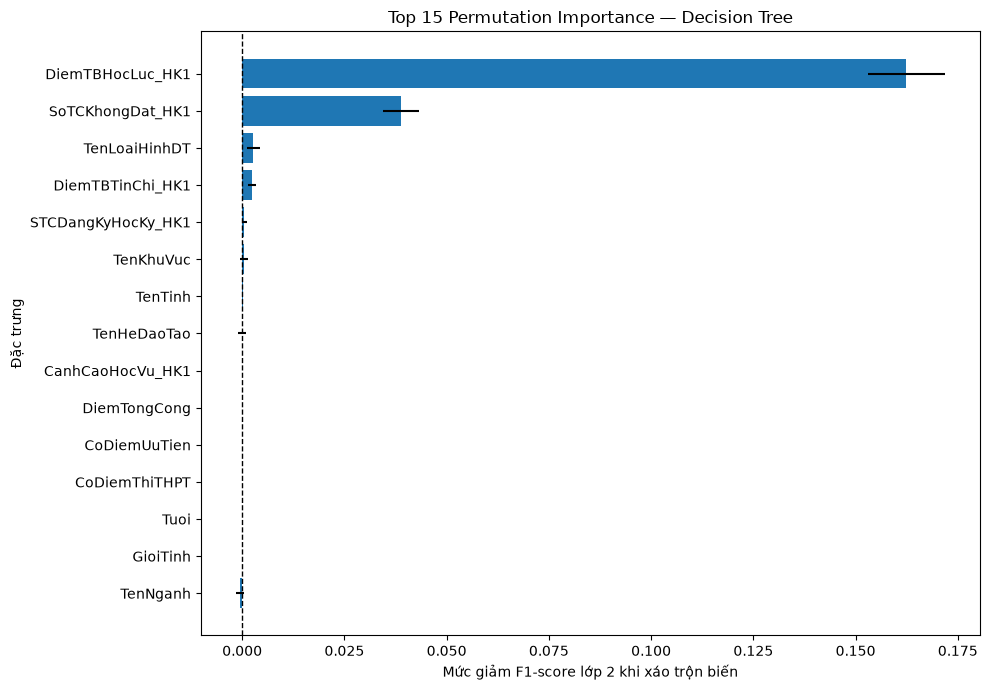

In [30]:
top_features = importance_df.head(15).sort_values(
    "Importance_Mean"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance_Mean"],
    xerr=top_features["Importance_Std"]
)

plt.axvline(0, color="black", linestyle="--", linewidth=1)

plt.title("Top 15 Permutation Importance — Decision Tree")
plt.xlabel("Mức giảm F1-score lớp 2 khi xáo trộn biến")
plt.ylabel("Đặc trưng")
plt.tight_layout()
plt.show()

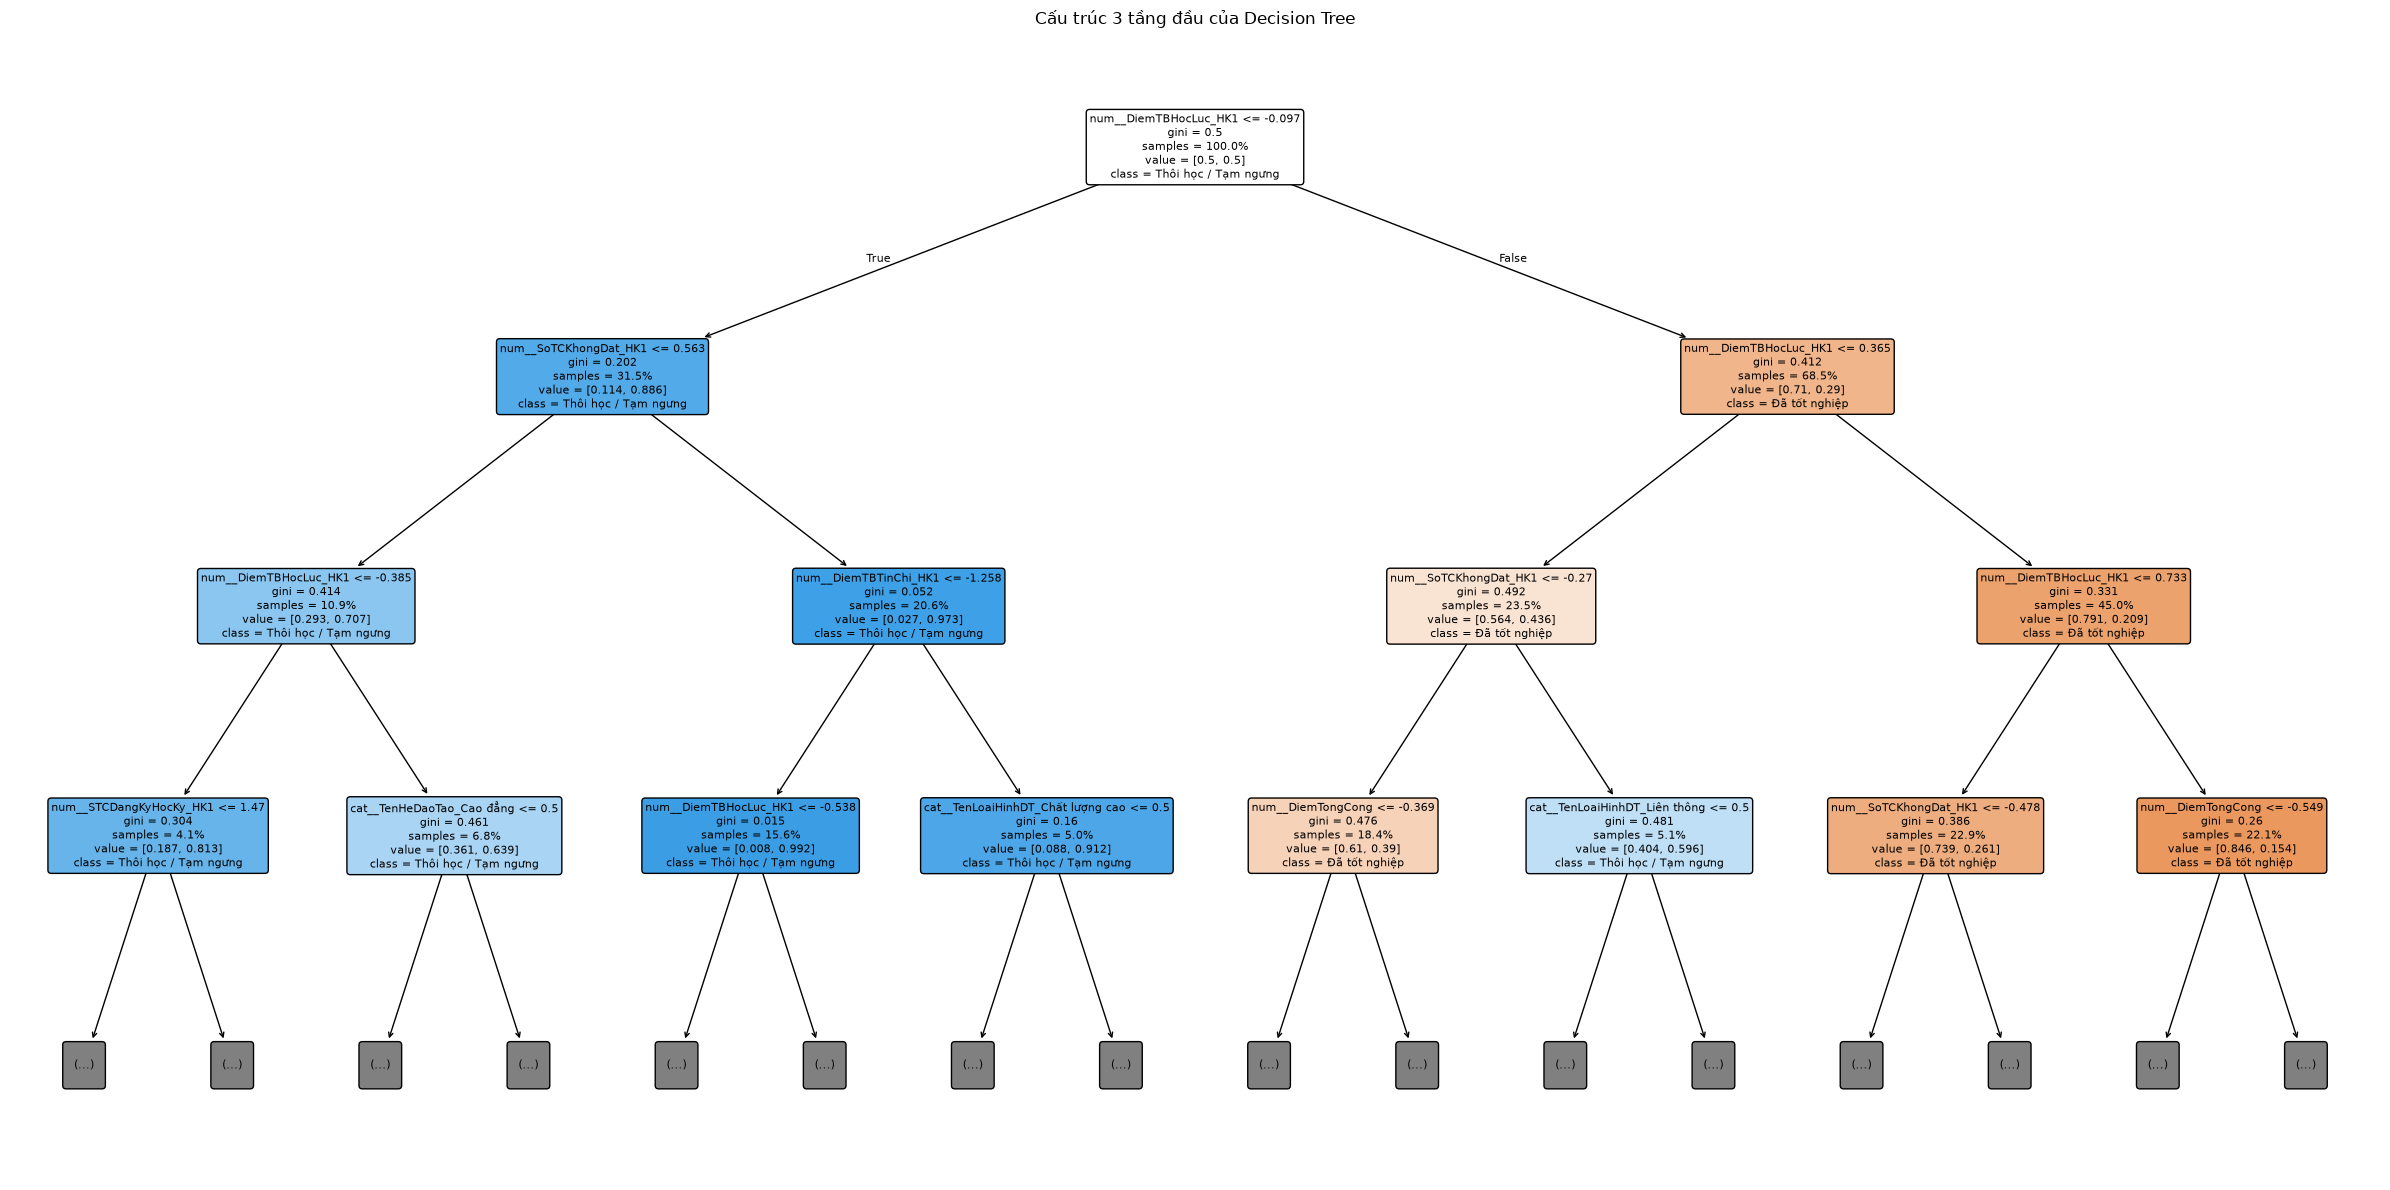

In [31]:
from sklearn.tree import plot_tree

tree_clf = final_model.named_steps["classifier"]
preprocessor_fitted = final_model.named_steps["preprocessor"]

transformed_feature_names = (
    preprocessor_fitted.get_feature_names_out()
)

class_name_map = {
    1: "Đã tốt nghiệp",
    2: "Thôi học / Tạm ngưng"
}

tree_class_names = [
    class_name_map.get(int(label), str(label))
    for label in tree_clf.classes_
]

plt.figure(figsize=(24, 12))

plot_tree(
    tree_clf,
    feature_names=transformed_feature_names,
    class_names=tree_class_names,
    max_depth=3,
    filled=True,
    rounded=True,
    proportion=True,
    fontsize=8
)

plt.title("Cấu trúc 3 tầng đầu của Decision Tree")
plt.tight_layout()
plt.show()

In [32]:
comparison_df.to_excel("ComparisonDF.xlsx",index= False) 